In [158]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

In [159]:
execfile = pd.ExcelFile("D:\\Data science\\Assignments\\Questions\\Clustering\\Clustering\\EastWestAirlines.xlsx")
execfile.sheet_names

['Description', 'data']

In [160]:
df = execfile.parse('data')
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [161]:
df.isnull().sum()
# no null values

ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

In [ ]:
# # Remove outliers using the IQR method
# Q1 = df.quantile(0.25)
# Q3 = df.quantile(0.75)
# IQR = Q3 - Q1
# df = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]
# df

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
5,6,16420,0,1,1,1,0,0,0,0,6942,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3994,4017,18476,0,1,1,1,8525,4,200,1,1403,1
3995,4018,64385,0,1,1,1,981,5,0,0,1395,1
3996,4019,73597,0,3,1,1,25447,8,0,0,1402,1
3997,4020,54899,0,1,1,1,500,1,500,1,1401,0


In [162]:
X = df.iloc[:,1:]
X.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143,0,1,1,1,174,1,0,0,7000,0
1,19244,0,1,1,1,215,2,0,0,6968,0
2,41354,0,1,1,1,4123,4,0,0,7034,0
3,14776,0,1,1,1,500,1,0,0,6952,0
4,97752,0,4,1,1,43300,26,2077,4,6935,1


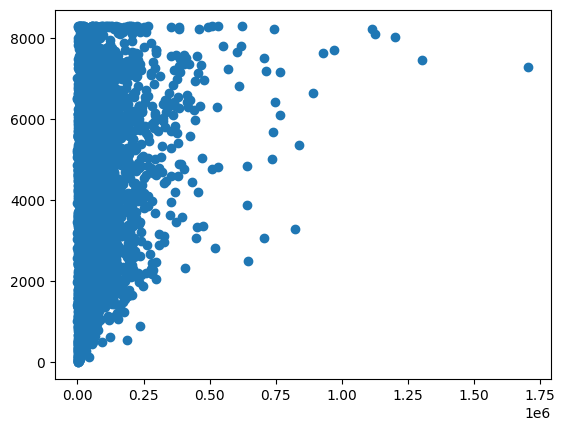

In [163]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10])
plt.show()

# K-means

In [164]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 2)
df["Kmeans"] = model.fit_predict(X)

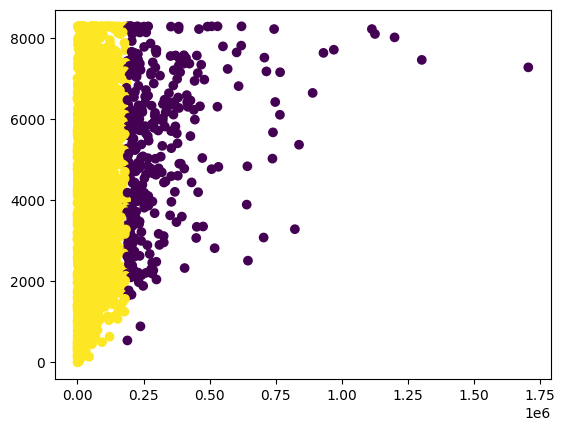

In [165]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["Kmeans"])
plt.show()

In [166]:
score = silhouette_score(X, df["Kmeans"])
print("Kmeans - score:",np.round(score,2))

Kmeans - score: 0.74


In [167]:
scores = []
for i in range(2,11):
    model = KMeans(n_clusters=i)
    df["Kmeans"] = model.fit_predict(X)
    scores.append(silhouette_score(X, df["Kmeans"]))
    

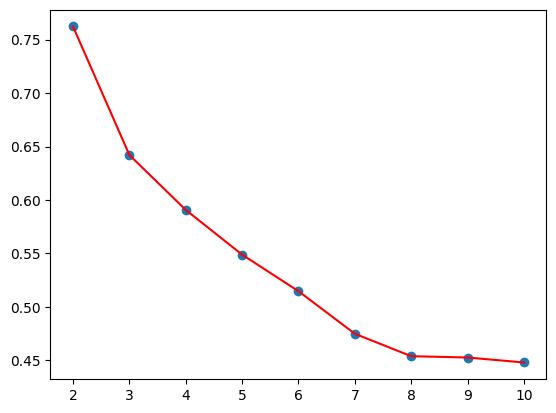

In [168]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

# hierarchical clustering 

In [169]:
from sklearn.cluster import AgglomerativeClustering

### Single

In [170]:
model = AgglomerativeClustering(n_clusters=5, linkage='single')
df["single"] = model.fit_predict(X)

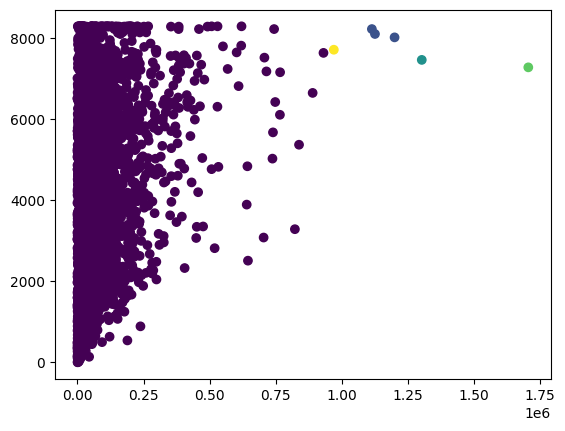

In [171]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["single"])
plt.show()

In [172]:
score = silhouette_score(X, df["single"])
print("Single - score:",np.round(score,2))

Single - score: 0.89


### complete

In [243]:
model = AgglomerativeClustering(n_clusters=5, linkage='complete')
df["complete"] = model.fit_predict(X)

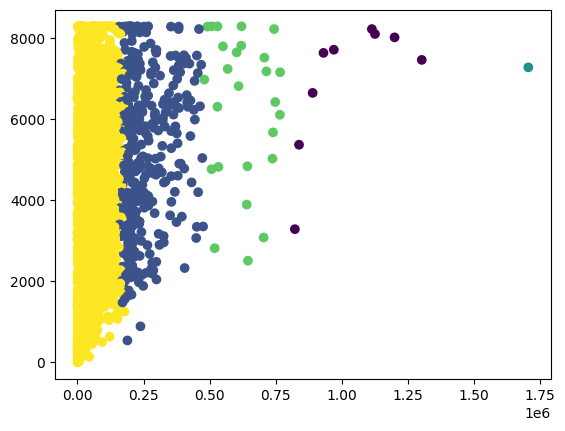

In [244]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["complete"])
plt.show()

In [245]:
score = silhouette_score(X, df["complete"])
print("complete - score:",np.round(score,2))

complete - score: 0.69


### Average

In [176]:
model = AgglomerativeClustering(n_clusters=5, linkage='average')
df["average"] = model.fit_predict(X)

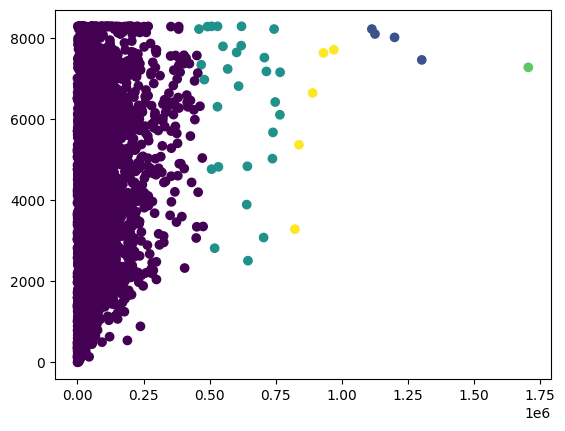

In [177]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["average"])
plt.show()

In [246]:
score = silhouette_score(X, df["average"])
print("average - score:",np.round(score,2))

average - score: 0.84


### Ward

In [179]:
model = AgglomerativeClustering(n_clusters=5, linkage='ward')
df["ward"] = model.fit_predict(X)

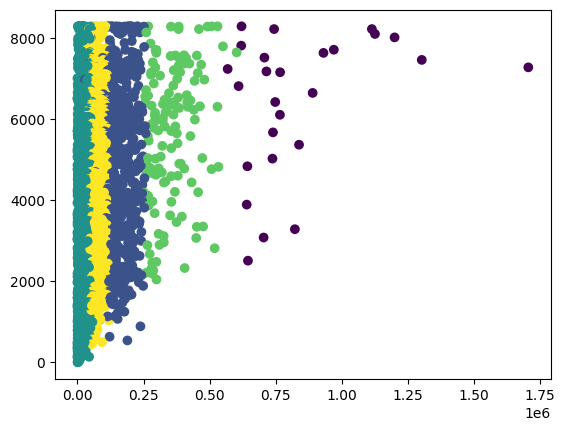

In [180]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["ward"])
plt.show()

In [247]:
score = silhouette_score(X, df["ward"])
print("ward - score:",np.round(score,2))

ward - score: 0.33


In [182]:
scores = []
for i in range(2,11):
    model = AgglomerativeClustering(n_clusters=i, linkage='ward')
    df["ward"] = model.fit_predict(X)
    scores.append(silhouette_score(X, df["ward"]))

scores = pd.DataFrame(scores, index=range(2,11), columns=["score"])
scores


,score
2,0.650795
3,0.649557
4,0.612437
5,0.488494
6,0.488892
7,0.479435
8,0.480173
9,0.476760
10,0.330365


##### for changing n_cluster numbers

In [183]:
scores = []
for i in range(2,11):
    model = AgglomerativeClustering(n_clusters=i, linkage='ward')
    df["ward"] = model.fit_predict(X)
    score = silhouette_score(X, df["ward"])
    scores.append(score)


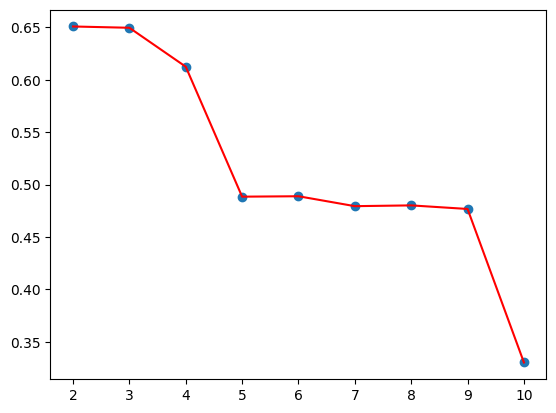

In [184]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

# DBSCAN

In [185]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [186]:
ss = StandardScaler()
ss_X = ss.fit_transform(X)


In [237]:
model = DBSCAN(eps=4, min_samples=80)
df["DBSCAN"] = model.fit_predict(ss_X)

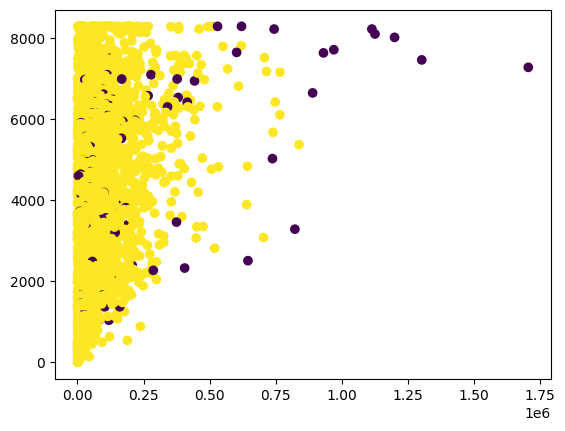

In [238]:
plt.scatter(X.iloc[:,0:1],X.iloc[:,9:10], c=df["DBSCAN"])
plt.show()

In [239]:
score = silhouette_score(X, df["DBSCAN"])
print("DBSCAN - score:",np.round(score,2))

DBSCAN - score: 0.58


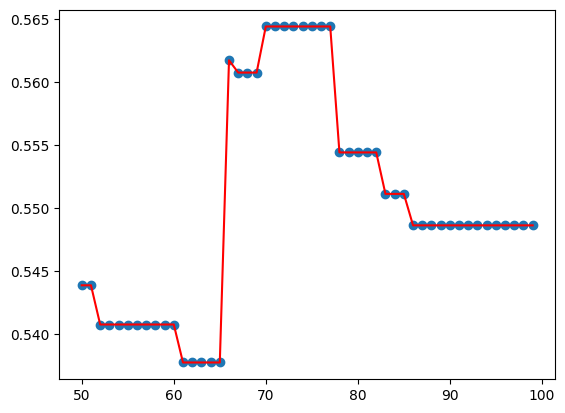

In [236]:
scores = []
for i in range(50, 100):
    model = DBSCAN(eps=5, min_samples=i)
    df["DBSCAN"] = model.fit_predict(ss_X)
    scores.append(silhouette_score(X, df["DBSCAN"]))

plt.scatter(range(50, 100), scores)
plt.plot(range(50, 100), scores, color='red')
plt.show()

In [242]:
df['DBSCAN'].value_counts()
# to check the ouliers

 0    3877
-1     122
Name: DBSCAN, dtype: int64

this proves that DBSCAN is not good for this data set  
k -means and aglamerative(Average linkage) is the best clustring method 